# Multi-Sheet Macroeconomic & Nowcasting Models: GDP, Inflation Rate, and CPI

This notebook combines information from multiple relevant sheets in the Excel workbook:

- **Table IXC:** Quarterly Gross Domestic Product (aggregated to annual fiscal GDP)
- **Table IB:** Consumer Price Index (CPI), 12-Month Average Inflation Rate, Industrial Production, Imports, Foreign Exchange Reserves, and Exchange Rates
- **Table IV:** Merchandise Exports

**Targets (in order of priority):**
1. **GDP** (Nominal GDP, Taka in Crore)
2. **Inflation Rate** (12-Month Average Inflation %, Base: 2021-22 and 2005-06)
3. **CPI** (Point-to-Point Consumer Price Index)

**Baseline models:** Linear Regression, Decision Tree Regressor, and K-Nearest Neighbors (KNN) Regressor.

The notebook uses robust EDA, multi-sheet preprocessing, feature scaling, and three baseline models.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Workbook

In [2]:
file_path = 'Apr26 (For Shounok 16.07.2026).xlsx'

excel_file = pd.ExcelFile(file_path)

print('Number of sheets:', len(excel_file.sheet_names))
print(excel_file.sheet_names[:15])

Number of sheets: 45
['Cover Page', 'Contents', 'Table IA', 'Table IB', 'TableIIA', 'TableIIB', 'TableIIC ', 'Table IID', 'Table IIE', 'Table IIF', 'Table IIG', 'Table III A', 'Table IIIB', 'Table IV', 'Table V']


## 3. Load the Relevant Sheets

In [3]:
gdp_raw = pd.read_excel(file_path, sheet_name='TableIXC', header=None)
macro_raw = pd.read_excel(file_path, sheet_name='Table IB', header=None)
export_raw = pd.read_excel(file_path, sheet_name='Table IV', header=None)

print('Table IXC (GDP) shape:', gdp_raw.shape)
print('Table IB (Macro/Inflation) shape:', macro_raw.shape)
print('Table IV (Exports) shape:', export_raw.shape)

Table IXC (GDP) shape: (58, 39)
Table IB (Macro/Inflation) shape: (268, 16)
Table IV (Exports) shape: (278, 42)


## 4. Preview the Source Sheets

In [4]:
print('Table IXC: Quarterly GDP')
display(gdp_raw.head(8))

print('Table IB: Economic Indicators & Inflation')
display(macro_raw.head(8))

print('Table IV: Merchandise Exports')
display(export_raw.head(8))

Table IXC: Quarterly GDP


,0,1,2,3,4,5,6,7,8,9,...,29,30,31,32,33,34,35,36,37,38
0,NaN,NaN,NaN,,QUARTERLY GROSS DOMESTIC PRODUCT,NaN,NaN,NaN,NaN,NaN,...,NaN,OF BANGLADESH (Base:2015-16) ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(Taka in crore),NaN,NaN
2,Period,NaN,Agriculture,Industry,NaN,NaN,NaN,NaN,Services,NaN,...,NaN,NaN,NaN,NaN,NaN,GVA at Basic Price,Tax Less Subsidy,GDP at Constant Price,Growth Rate,Period
3,NaN,NaN,"Agricul-ture, Forestry & Fishing",Mining & Quarry-ing,Manufa-cturing,"Electri-city, Gas and Water Supply",Constr-uctions,Total,"Whole-sale & Retail Trade, Repair","Transportation, Accomodation and Food",...,Finan-cial & Insurance Activities,"Real Estate,Professional & Administrative","Public Administration, Health & Education","Arts, Recreation &Other Service activities",Total,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,1,2,3,4,5,6=(2+..+5),7,8,...,26,27,28,29,30=(24+..+29),31=(18+23+30),32,33=(31+32),34,NaN
5,(a) Current Market Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2015-16,July-Sep,61639,7042,97951,6423,35105,146521,65169,47435,...,14016,51834,41234,27717,250851,462591,21700,484291,…,Q1
7,2015-16,Oct-Dec,75020,7828,100244,5928,37499,151499,70325,51229,...,15602,51899,30490,28773,248343,477395,22766,500161,…,Q2


Table IB: Economic Indicators & Inflation


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,NaN,NaN,NaN,NaN,NaN,NaN,SELECTED ECONOMIC,NaN,NaN,NaN,INDICATORS,NaN,NaN,NaN,NaN,TABLE-IB
1,NaN,NaN,NaN,NaN,NaN,NaN,"( Inflation, Production Index, Foreign Trade,",NaN,NaN,NaN,Forex Reserves & Exchange Rate),NaN,NaN,NaN,NaN,NaN
2,Period,Months,Rate of Inflation in Bangladesh Measured by ...,NaN,NaN,NaN,Index of Industrial Production,NaN,NaN,NaN,Foreign Trade (Million US $),NaN,Foreign Exchange Reserves,NaN,Weighted Average Exchange Rate,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,"Index of Manufacturing, Mining & Electricity",NaN,NaN,NaN,Foreign Trade (during the period),NaN,(Million US $),NaN,Tk/US Dollar,NaN
4,NaN,NaN,Point- to- Point (Base: 2021-22=100),Point- to- Point (Base: 2005-06=100),12- Month Average (Base: 2021-22=100),12- Month Average (Base: 2005-06=100),Manufacturing,Mining,Electricity,Total Industries,Exports (Shipment),Import (Shipment),Foreign Exchange Reserves,Foreign Exchange Reserves (as per BPM6 ),Period Average,End Period
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,1,2,3,4,5,6,7,8,9,10,11,12,13,14
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Table IV: Merchandise Exports


,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,TABLE-IV (Concld.),NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(Taka in crore),NaN,NaN
2,Period,NaN,MERCHANDISE EXPORTS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,IMPORTS,NaN,NaN,NaN,NaN,NaN,Total Imports,Balance of Trade,Period,NaN
3,NaN,NaN,Raw Jute,Jute Manufactures,Tea,Leather and Leather Manufactures,"Fish, Shrimp & Prawns",Ready made Garments,"Naptha, Furnace oil & Bitumen",News Print,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Textile & articles thereof,Staple fibres,"Iron,Steel and other base metals",Capital machinery,Others (Including EPZ),Total (15 through 35),NaN,NaN,NaN,NaN
5,NaN,NaN,1,2,3,4,5,6,7,8,...,31,32,33,34,35,36,37=(14+36),38=(11-37),NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Preprocessing

## 5. Clean Table IXC: Aggregate Quarterly GDP to Annual Fiscal GDP

In [5]:
gdp_q = gdp_raw.iloc[6:58, [0, 1, 17]].copy()
gdp_q.columns = ['FY', 'Qtr', 'GDP']
gdp_q['FY_clean'] = gdp_q['FY'].astype(str).str.replace('P','', regex=False).str.replace('p','', regex=False)
gdp_q['GDP'] = pd.to_numeric(gdp_q['GDP'], errors='coerce')

annual_gdp = gdp_q.dropna(subset=['GDP']).groupby('FY_clean')['GDP'].sum().reset_index()
print('Annual GDP records:', annual_gdp.shape[0])
display(annual_gdp.head())

Annual GDP records: 11


,FY_clean,GDP
0,2015-16,2075820.0
1,2016-17,2324307.0
2,2017-18,2639246.0
3,2018-19,2951429.0
4,2019-20,3170468.0


## 6. Clean Table IB: Extract Inflation, CPI, and Macro Indicators

In [6]:
ann_ib = macro_raw.iloc[8:44, [0, 1, 2, 3, 4, 5, 9, 11, 12, 14]].copy()
ann_ib.columns = ['Period', 'Month', 'Point_New', 'Point_Old', 'Avg_New', 'Avg_Old', 'TotalInd', 'Imports', 'Forex', 'ExchAvg']
ann_ib = ann_ib[ann_ib['Month'].isna() & ann_ib['Period'].astype(str).str.match(r'^\d{4}-\d{2}P?$', na=False)].copy()

ann_ib['FY_clean'] = ann_ib['Period'].str.replace('P','', regex=False)
for c in ['Point_New', 'Point_Old', 'Avg_New', 'Avg_Old', 'TotalInd', 'Imports', 'Forex', 'ExchAvg']:
    ann_ib[c] = pd.to_numeric(ann_ib[c].astype(str).str.replace('\xa0','', regex=False).str.replace(',','', regex=False).str.replace('…','nan', regex=False), errors='coerce')

ann_ib['Inflation_Rate'] = ann_ib['Avg_New'].fillna(ann_ib['Avg_Old'])
ann_ib['CPI'] = ann_ib['Point_New'].fillna(ann_ib['Point_Old'])

macro_data = ann_ib[['FY_clean', 'Inflation_Rate', 'CPI', 'TotalInd', 'Imports', 'Forex', 'ExchAvg']]
print('Annual macroeconomic records:', macro_data.shape[0])
display(macro_data.head())

Annual macroeconomic records: 32


,FY_clean,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg
8,1994-95,NaN,NaN,83.0,3472.5,5834.0,NaN
9,1995-96,NaN,NaN,79.0,3882.4,6931.0,NaN
10,1996-97,3.96,NaN,80.0,4418.3,7152.0,NaN
11,1997-98,8.66,NaN,81.0,5161.2,7520.0,NaN
12,1998-99,7.06,NaN,72.0,5312.8,8006.0,NaN


## 7. Clean Table IV: Annual Merchandise Exports

In [7]:
ann_4 = export_raw.iloc[9:45].copy()
ann_4 = ann_4[ann_4[0].astype(str).str.match(r'^\d{4}-\d{2}$', na=False)].copy()
ann_4['FY_clean'] = ann_4[0].astype(str)
ann_4['Exports'] = pd.to_numeric(ann_4[12].astype(str).str.replace('\xa0','', regex=False).str.replace(',','', regex=False), errors='coerce')

exports_data = ann_4[['FY_clean', 'Exports']]
print('Annual export records:', exports_data.shape[0])
display(exports_data.head())

Annual export records: 30


,FY_clean,Exports
9,1993-94,9799.0
10,1994-95,13130.0
11,1995-96,13857.0
12,1996-97,16564.0
13,1997-98,20393.0


## 8. Merge the Cleaned Sheets into a Unified Dataset

In [8]:
df = annual_gdp.merge(macro_data, on='FY_clean', how='inner') \
               .merge(exports_data, on='FY_clean', how='inner')

df = df.dropna().reset_index(drop=True)

print('Final merged dataset shape:', df.shape)
display(df.head())

Final merged dataset shape: (8, 9)


,FY_clean,GDP,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg,Exports
0,2015-16,2075820.0,5.920000,5.53,100.000000,43122.5,30355.56,78.268600,236803.1
1,2016-17,2324307.0,5.440000,5.94,110.685356,47005.2,33679.38,79.133000,239656.2
2,2017-18,2639246.0,5.780000,5.54,125.719552,58865.3,32943.46,82.107700,267179.8
3,2018-19,2951429.0,5.480000,5.52,143.889228,59914.6,32716.51,84.020800,296983.9
4,2019-20,3170468.0,5.647611,6.02,145.071764,54784.8,36037.03,84.781146,265453.5


## 9. Check Missing Values & Descriptive Statistics

In [9]:
print('Missing values in final dataset:')
print(df.isnull().sum())

display(df.describe())

Missing values in final dataset:
FY_clean          0
GDP               0
Inflation_Rate    0
CPI               0
TotalInd          0
Imports           0
Forex             0
ExchAvg           0
Exports           0
dtype: int64


,GDP,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg,Exports
count,8.000000e+00,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
mean,3.144251e+06,6.124701,6.436250,145.831766,61688.875000,35644.138721,85.678368,300359.387500
std,8.240738e+05,1.193738,1.497388,33.756478,14966.542665,5622.671083,8.659508,69010.729119
min,2.075820e+06,5.440000,5.520000,100.000000,43122.500000,30355.560000,78.268600,236803.100000
25%,2.560511e+06,5.540000,5.537500,121.961003,52839.900000,32338.132500,81.364025,259004.175000
50%,3.060948e+06,5.713806,5.790000,144.480496,59389.950000,33311.420000,84.400973,277629.950000
75%,3.640567e+06,5.977500,6.405000,166.833674,67961.425000,37484.454942,85.202900,316981.975000
max,4.490835e+06,9.020000,9.740000,197.390000,89162.300000,46391.440000,105.916700,431742.300000


# Exploratory Data Analysis (EDA)

## 10. Nominal GDP Over Time

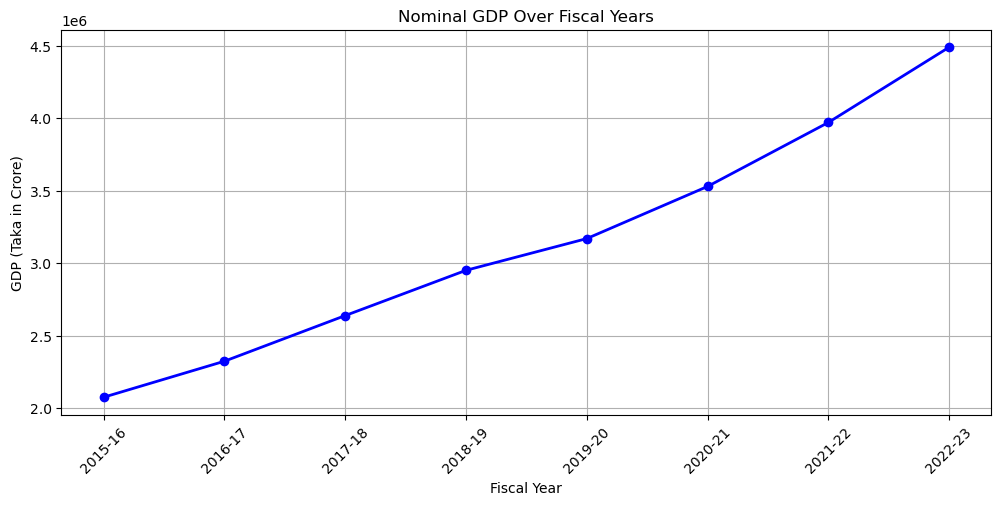

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df['FY_clean'], df['GDP'], marker='o', color='b', lw=2)
plt.title('Nominal GDP Over Fiscal Years')
plt.xlabel('Fiscal Year')
plt.ylabel('GDP (Taka in Crore)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

## 11. Inflation Rate and CPI Over Time

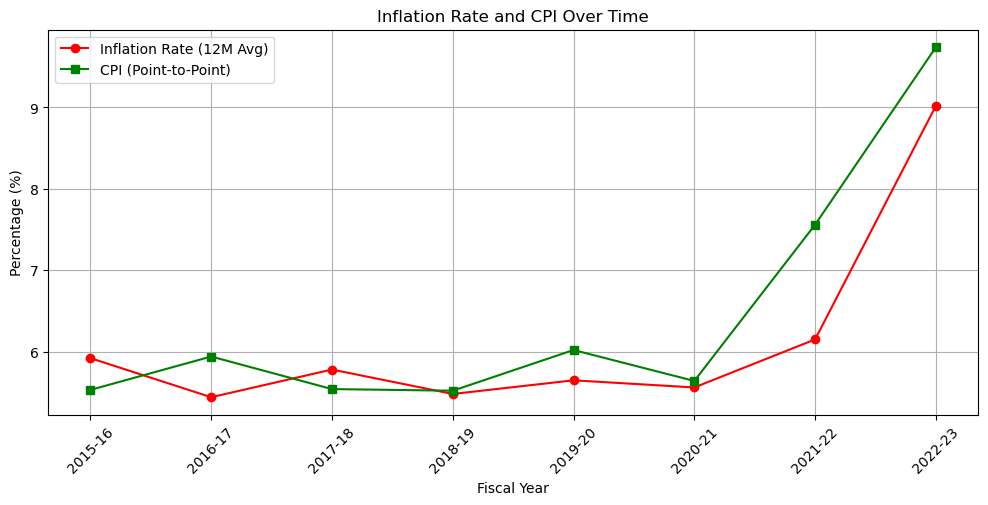

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(df['FY_clean'], df['Inflation_Rate'], marker='o', color='r', label='Inflation Rate (12M Avg)')
plt.plot(df['FY_clean'], df['CPI'], marker='s', color='g', label='CPI (Point-to-Point)')
plt.title('Inflation Rate and CPI Over Time')
plt.xlabel('Fiscal Year')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid()
plt.show()

## 12. Distribution of GDP

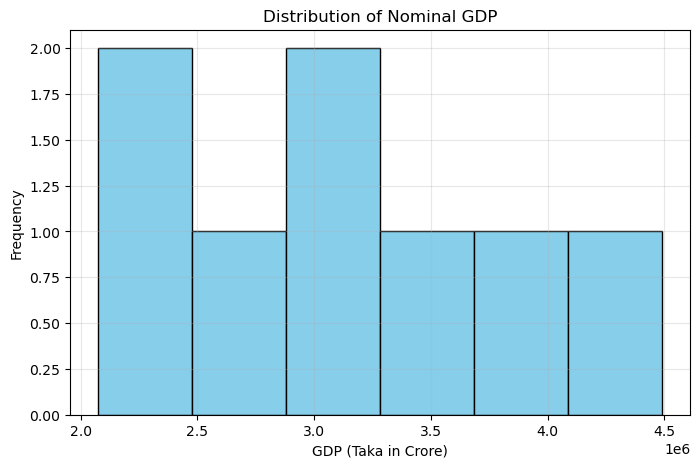

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(df['GDP'], bins=6, color='skyblue', edgecolor='black')
plt.title('Distribution of Nominal GDP')
plt.xlabel('GDP (Taka in Crore)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

## 13. Exports vs GDP Scatter Plot

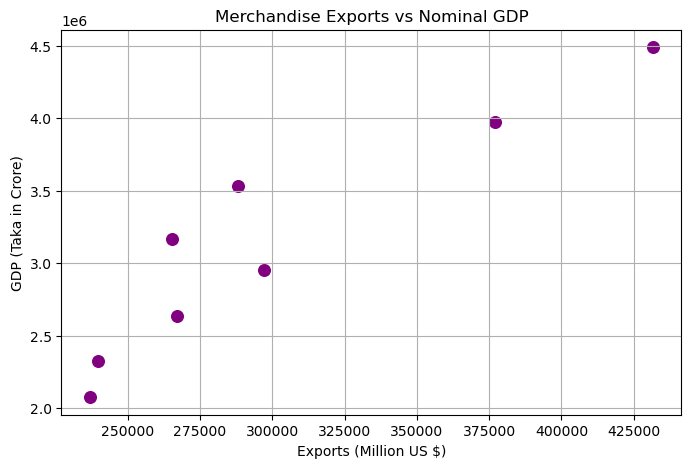

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Exports'], df['GDP'], color='purple', s=70)
plt.title('Merchandise Exports vs Nominal GDP')
plt.xlabel('Exports (Million US $)')
plt.ylabel('GDP (Taka in Crore)')
plt.grid()
plt.show()

## 14. Inflation vs GDP Scatter Plot

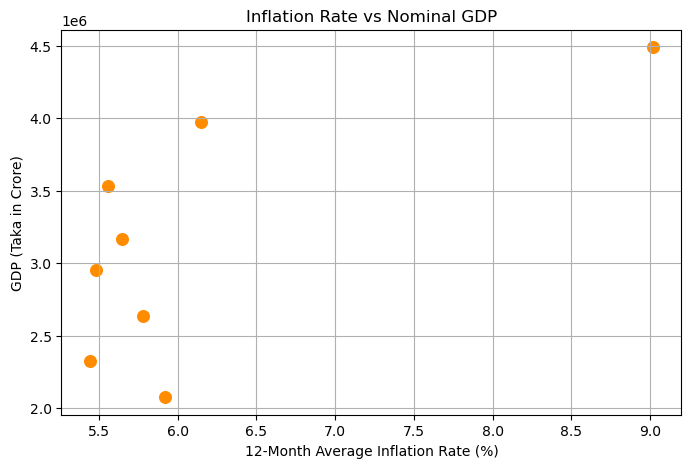

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Inflation_Rate'], df['GDP'], color='darkorange', s=70)
plt.title('Inflation Rate vs Nominal GDP')
plt.xlabel('12-Month Average Inflation Rate (%)')
plt.ylabel('GDP (Taka in Crore)')
plt.grid()
plt.show()

## 15. Correlation Matrix Heatmap

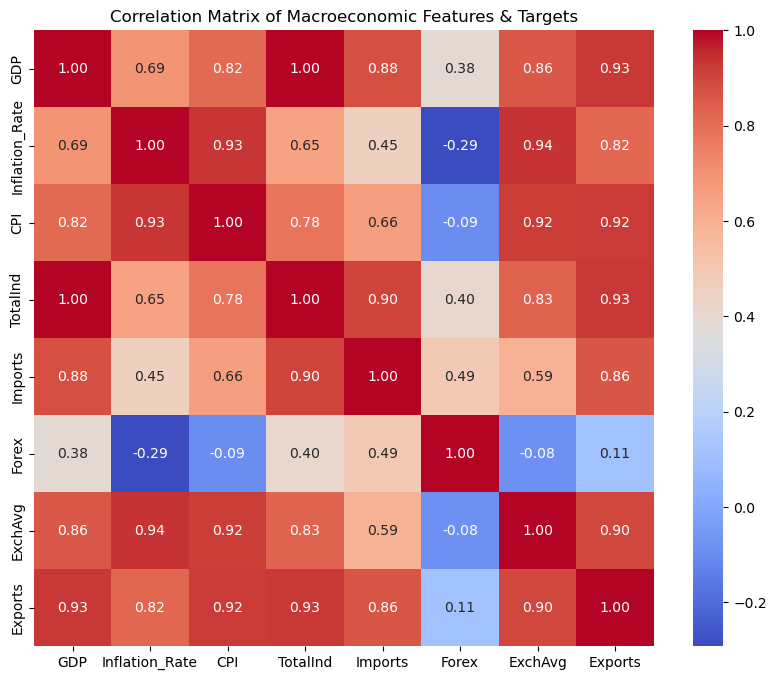

In [15]:
corr_columns = ['GDP', 'Inflation_Rate', 'CPI', 'TotalInd', 'Imports', 'Forex', 'ExchAvg', 'Exports']

plt.figure(figsize=(10, 8))
correlation = df[corr_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix of Macroeconomic Features & Targets')
plt.show()

# Multi-Target Baseline Model Pipeline (Priority Order: GDP -> Inflation_Rate -> CPI)


 MODELING PIPELINE FOR TARGET: GDP


,Model,MAE,RMSE,R2 Score
0,Linear Regression,225372.6136,267956.1218,0.8025
1,Decision Tree,712458.0000,724895.0917,-0.4455
2,KNN,37067.2500,37265.7514,0.9962


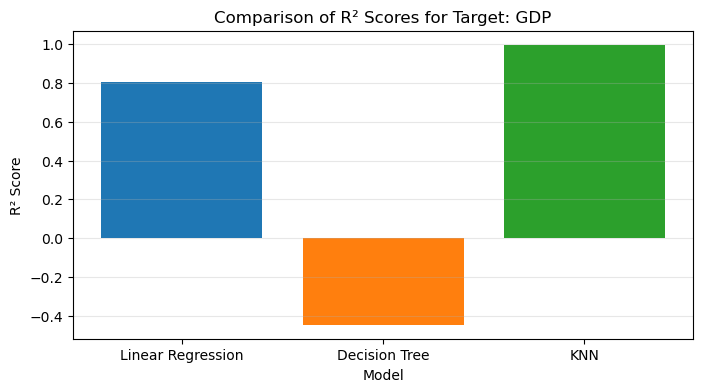


 MODELING PIPELINE FOR TARGET: Inflation_Rate


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.4611,0.5680,-88.6322
1,Decision Tree,0.2838,0.3450,-32.0661
2,KNN,0.3744,0.3761,-38.2902


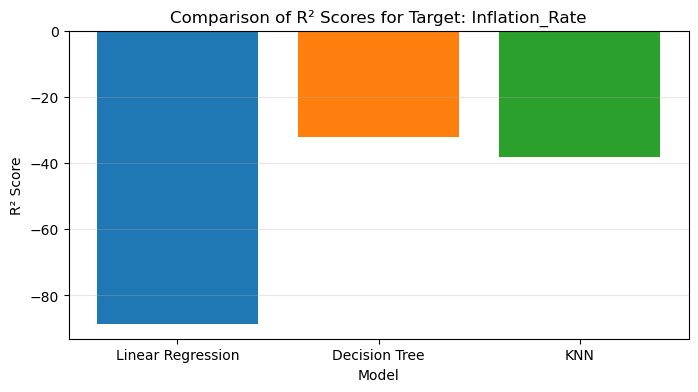


 MODELING PIPELINE FOR TARGET: CPI


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.7706,0.8886,-34.0938
1,Decision Tree,0.3950,0.3953,-5.9444
2,KNN,0.7775,0.8621,-32.0339


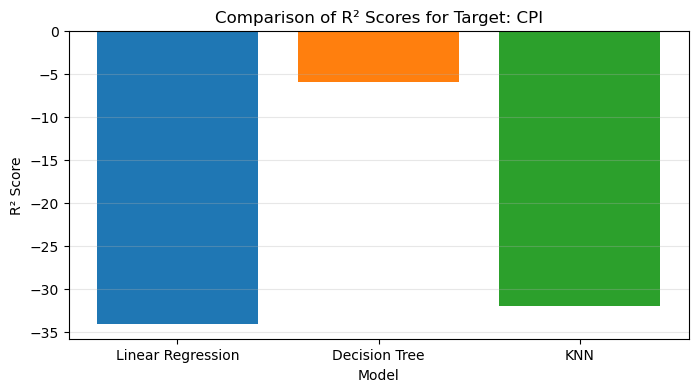

In [16]:
targets = ['GDP', 'Inflation_Rate', 'CPI']
all_features = [c for c in df.columns if c not in ['FY_clean'] + targets]

for target in targets:
    print(f'\n==================================================')
    print(f' MODELING PIPELINE FOR TARGET: {target}')
    print(f'==================================================')
    
    other_targets = [t for t in targets if t != target]
    feature_cols = all_features + other_targets
    
    X = df[feature_cols]
    y = df[target]
    
    # Train-Test Split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42
    )
    
    # Feature Scaling for KNN
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 1. Linear Regression
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    lr_pred = lr.predict(X_test)
    
    lr_mae = mean_absolute_error(y_test, lr_pred)
    lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
    lr_r2 = r2_score(y_test, lr_pred)
    
    # 2. Decision Tree Regressor
    dt = DecisionTreeRegressor(random_state=42)
    dt.fit(X_train, y_train)
    dt_pred = dt.predict(X_test)
    
    dt_mae = mean_absolute_error(y_test, dt_pred)
    dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
    dt_r2 = r2_score(y_test, dt_pred)
    
    # 3. K-Nearest Neighbors (KNN)
    knn = KNeighborsRegressor(n_neighbors=2)
    knn.fit(X_train_scaled, y_train)
    knn_pred = knn.predict(X_test_scaled)
    
    knn_mae = mean_absolute_error(y_test, knn_pred)
    knn_rmse = np.sqrt(mean_squared_error(y_test, knn_pred))
    knn_r2 = r2_score(y_test, knn_pred)
    
    # Results Summary DataFrame
    results = pd.DataFrame({
        'Model': ['Linear Regression', 'Decision Tree', 'KNN'],
        'MAE': [lr_mae, dt_mae, knn_mae],
        'RMSE': [lr_rmse, dt_rmse, knn_rmse],
        'R2 Score': [lr_r2, dt_r2, knn_r2]
    })
    
    display(results.round(4))
    
    # Visual comparison bar chart of R2 scores for current target
    plt.figure(figsize=(8, 4))
    plt.bar(results['Model'], results['R2 Score'], color=['tab:blue', 'tab:orange', 'tab:green'])
    plt.title(f'Comparison of R² Scores for Target: {target}')
    plt.xlabel('Model')
    plt.ylabel('R² Score')
    plt.grid(axis='y', alpha=0.3)
    plt.show()